In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib
import numpy as np
import scipy.optimize
import odrpack

plt.rcParams["figure.dpi"] = 150
plt.rcParams["text.usetex"] = True
plt.rcParams["font.size"] = 12


# matplotlib.rcParams['mathtext.fontset'] = 'stix'
# matplotlib.rcParams['font.family'] = 'Computer Modern'


plt.rcParams['font.family'] = 'serif' # or 'sans-serif' or 'monospace'
plt.rcParams['font.serif'] = 'cmr10'
plt.rcParams['font.sans-serif'] = 'cmss10'
plt.rcParams['font.monospace'] = 'cmtt10'
plt.rcParams["axes.formatter.use_mathtext"] = True # to fix the minus signs
%config InlineBackend.figure_format = 'retina'
#plt.rcParams['axes.grid'] = True

In [2]:
def string_to_float_list(data_string: str):
    return np.array([float(x) for x in data_string.split()])

In [3]:
r_tube = 3.34
L_tube = 640.0

stopper_depth = 13.84
h_can = 111.26
r_can = 46.28 / 2

r_chamber = 39.30 / 2

In [4]:

temps = np.array([4.636, 18.530, 27.937, 39.198, 47.291, 18.854, 12.576])

temps = temps - temps[0]

h_chamber = np.array([21, 30, 36.1, 42.1, 44.0, 27.6, 19.5])


volumes = 1e-9 * np.pi * (r_tube**2 * L_tube + (h_can - stopper_depth) * r_can**2 + h_chamber * r_chamber**2)

#volumes_err = 1e-9 * np.pi * 


In [5]:
from statistics import linear_regression

import scipy.optimize
import scipy.signal


def linear_fit(x, m, x0):
    return m * (x - x0)


popt, pcov = scipy.optimize.curve_fit(linear_fit, temps, volumes)

slope = popt[0]
T0 = popt[1]

print(T0)

-278.39015318559973


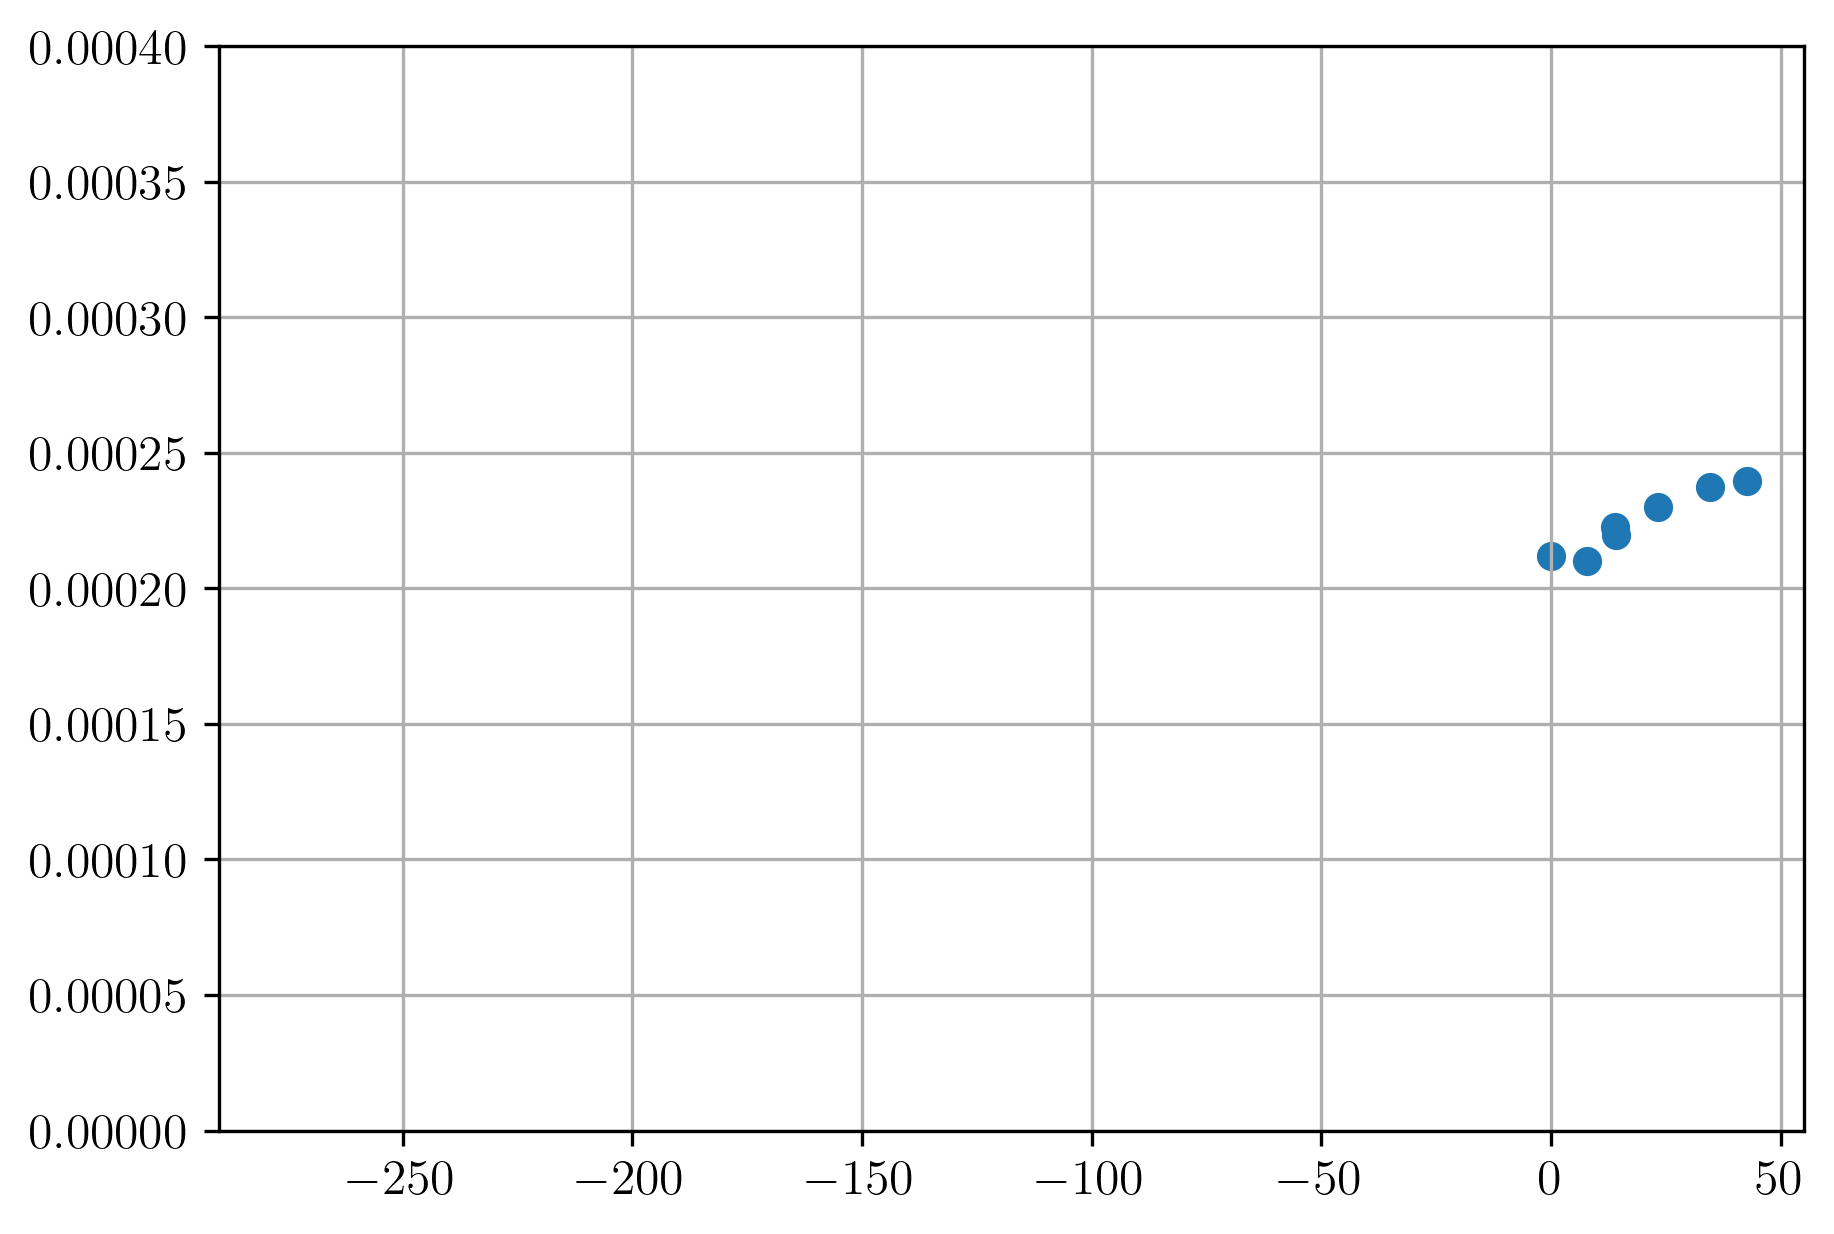

In [6]:
fig, ax = plt.subplots(1, figsize=(6, 4), layout="constrained")


ax.scatter(temps, volumes)

ax.set_ylim(0, 0.0004)
ax.set_xlim(-290, 55)

ax.grid()


chi2 = np.sum((volumes - linear_fit(temps, slope, T0))**2 / (0.5)**2)